# A/B-тест динамического ценообразования в маркетплейсе

В маркетплейсе с быстрой доставкой раньше действовала фиксированная комиссия: 5.5% от чека + $1.50 за заказ (`control`). Команда монетизации выкатила ML-алгоритм динамического сбора (`experimental`), который меняет комиссию в зависимости от чека, нагрузки и тарифа пользователя.

Предварительный отчет выглядит хорошо: средняя комиссия на заказ выросла больше чем на 12%. Но в поддержку начали приходить жалобы, и есть риск, что высокий сбор на небольших заказах отпугивает покупателей. Задача: почистить логи, проверить сплит, оценить эффект через бутстрап (BCa) и понять, как алгоритм влияет на удержание и юнит-экономику.

Данные (`marketplace_orders_experiment.csv`, 4 недели):
- `order_id`, `user_id`, `timestamp`, `group` (`control` / `experimental`)
- `platform` (`iOS`, `Android`, `Web`), `user_tier` (`Standard`, `Plus`, `Premium`)
- `cart_value` - стоимость товаров в корзине (GMV, USD)
- `service_fee` - комиссия с покупателя (USD)
- `delivery_duration_min` - время доставки в минутах
- `discount_applied` - скидка по промокоду (USD)
- `review_score` - оценка заказа от 1 до 5
- `is_returned` - возврат или отмена заказа (0/1)
- `reordered_within_7d` - повторный заказ в течение 7 дней (0/1)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import bootstrap
import pingouin as pg

sns.set_theme(style="whitegrid")

df = pd.read_csv("marketplace_orders_experiment.csv")
df.head()

,order_id,user_id,timestamp,group,platform,user_tier,cart_value,service_fee,delivery_duration_min,discount_applied,review_score,is_returned,reordered_within_7d
0,ORD-0005209,U03192,2026-03-01 08:01:26,experimental,Android,Standard,29.5,5.3,33.1,10.3,5.0,0,0
1,ORD-0000048,U00030,2026-03-01 08:02:13,control,Android,Standard,46.4,4.0,31.4,8.3,5.0,0,0
2,ORD-0010841,U06567,2026-03-01 08:03:47,experimental,iOS,Premium,82.6,4.3,40.5,0.0,NaN,0,1
3,ORD-0011936,U07233,2026-03-01 08:06:45,control,Web,Standard,38.8,3.6,49.0,8.1,5.0,0,0
4,ORD-0003144,U01902,2026-03-01 08:11:42,control,iOS,Standard,37.7,3.6,32.6,2.6,3.0,0,1


## 1. Проверка и очистка данных

In [2]:
df.shape

(14075, 13)

In [3]:
df.isna().sum()

order_id                    0
user_id                     0
timestamp                   0
group                       0
platform                    0
user_tier                   0
cart_value                  0
service_fee                57
delivery_duration_min       0
discount_applied            0
review_score             5369
is_returned                 0
reordered_within_7d         0
dtype: int64

In [4]:
df.duplicated().sum(), (df["service_fee"] <= 0).sum(), (df["delivery_duration_min"] <= 0).sum()

(np.int64(28), np.int64(98), np.int64(42))

In [5]:
df_clean = (
    df.drop_duplicates()
    .query("service_fee > 0 and delivery_duration_min > 0")
)
len(df_clean), round((1 - len(df_clean) / len(df)) * 100, 2)

(13852, 1.58)

In [6]:
# Проверяем, что пользователи не попали в обе группы сразу
df_clean.groupby("user_id")["group"].nunique().value_counts()

group
1    8443
Name: count, dtype: int64

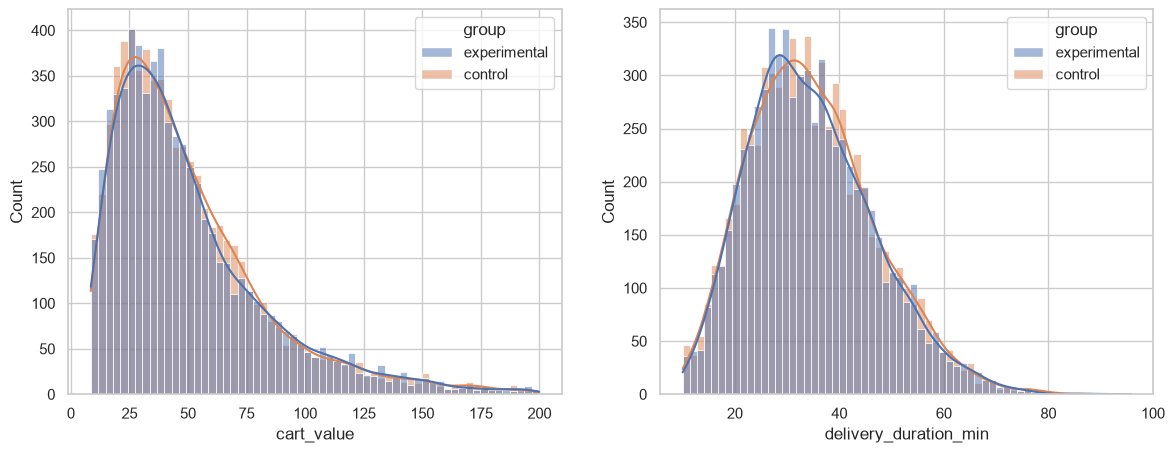

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df_clean.query("cart_value <= 200"), x="cart_value", hue="group", kde=True, ax=axes[0])
sns.histplot(data=df_clean, x="delivery_duration_min", hue="group", kde=True, ax=axes[1]);

Убрал около 1.6% битых записей: 28 дублей, нулевые/отрицательные комиссии и сбои по времени доставки. Пропуски в `review_score` (~38%) оставил как есть, оценки ставят не все.

Сплит чистый, все 8443 пользователя закреплены строго за одной группой. Распределения чека и времени доставки между контролем и тестом совпадают.

## 2. Разведочный анализ и Take-Rate

Посчитаем `take_rate_pct` - какой процент от стоимости корзины составляет сервисный сбор.

In [8]:
df_clean = df_clean.assign(take_rate_pct=lambda x: x["service_fee"] / x["cart_value"] * 100)
df_clean.groupby("group")[["cart_value", "service_fee", "take_rate_pct"]].describe().T

group                control  experimental
cart_value    count   7007.0        6845.0
              mean      58.2          57.4
              std      121.7         115.9
              min        8.5           8.5
              25%       26.6          26.6
              50%       42.1          41.6
              75%       65.7          65.5
              max     3061.4        3094.7
service_fee   count   7007.0        6845.0
              mean       4.7           5.3
              std        6.7           4.5
              min        2.0           1.5
              25%        3.0           4.2
              50%        3.8           4.9
              75%        5.1           5.6
              max      169.9         124.8
take_rate_pct count   7007.0        6845.0
              mean       9.9          13.5
              std        3.0           7.4
              min        5.5           4.0
              25%        7.8           9.0
              50%        9.1          10.8
              75%       11.1          18.1
              max       23.2          40.8

In [9]:
# Крупные заказы > $800
df_clean.query("cart_value > 800").groupby("group")["order_id"].count()

group
control         22
experimental    18
Name: order_id, dtype: int64

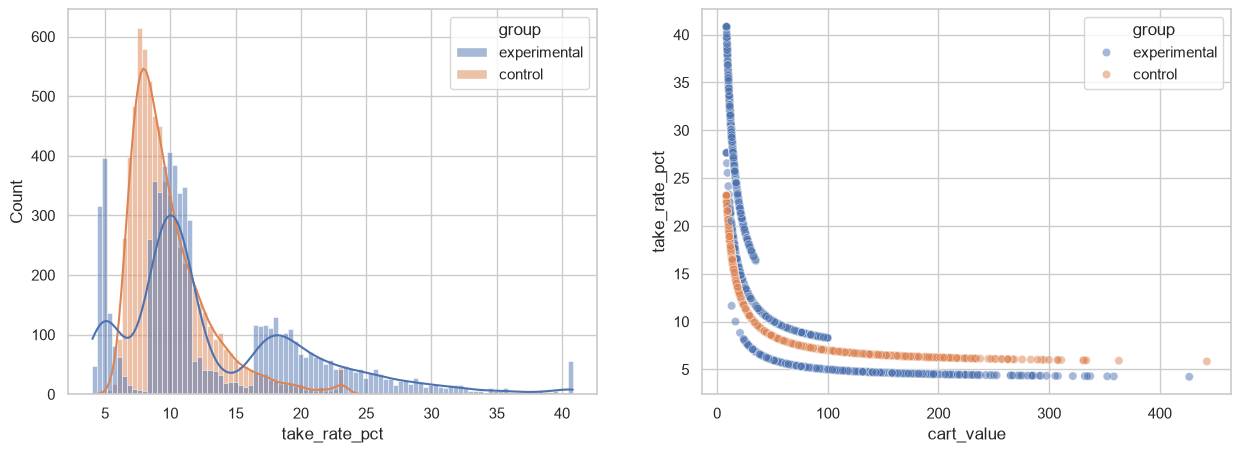

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(data=df_clean, x="take_rate_pct", hue="group", kde=True, ax=axes[0])
sns.scatterplot(data=df_clean.query("cart_value <= 500"), x="cart_value", y="take_rate_pct", hue="group", alpha=0.5, ax=axes[1]);

In [11]:
df_clean.groupby("group", as_index=False).agg(
    mean_review_score=("review_score", "mean"),
    returned_orders=("is_returned", "sum"),
    return_rate_pct=("is_returned", lambda x: x.mean() * 100),
)

,group,mean_review_score,returned_orders,return_rate_pct
0,control,3.9,153,2.2
1,experimental,3.7,157,2.3


На графике зависимости `take_rate_pct` от чека видно, как именно работает новый алгоритм: на маленьких заказах (около $15-$20) комиссия подскакивает до 25-40% от стоимости корзины, а на крупных (от $100 и выше) становится даже ниже базовых 5.5%.

Доля возвратов и отмен (`is_returned`) не изменилась и держится на уровне ~2.2%, но средняя оценка заказа (`review_score`) просела с 3.90 до 3.65.

## 3. Проверка выручки: t-тест и Bootstrap

У `service_fee` заметный правый хвост из-за крупных заказов, поэтому кроме обычного t-теста посмотрим на BCa-бутстрап (10 000 ресемплов) для разницы средних и медиан.

In [12]:
con_fee = df_clean.query("group == 'control'")["service_fee"]
exp_fee = df_clean.query("group == 'experimental'")["service_fee"]

pg.ttest(exp_fee, con_fee, confidence=0.95)

,T,dof,alternative,p_val,CI95,cohen_d,power,BF10
T_test,5.9,12248.6,two-sided,0.0,"[0.38, 0.76]",0.1,1.0,6.825e+05


In [13]:
boot_mean = bootstrap(
    (exp_fee, con_fee),
    statistic=lambda x, y, axis=-1: np.mean(x, axis=axis) - np.mean(y, axis=axis),
    n_resamples=10000,
    method="BCa",
    random_state=42,
)
boot_median = bootstrap(
    (exp_fee, con_fee),
    statistic=lambda x, y, axis=-1: np.median(x, axis=axis) - np.median(y, axis=axis),
    n_resamples=10000,
    method="BCa",
    random_state=42,
)

pd.DataFrame({
    "metric": ["mean_diff", "median_diff"],
    "point_est": [exp_fee.mean() - con_fee.mean(), exp_fee.median() - con_fee.median()],
    "ci_low": [boot_mean.confidence_interval.low, boot_median.confidence_interval.low],
    "ci_high": [boot_mean.confidence_interval.high, boot_median.confidence_interval.high],
}).round(3)

,metric,point_est,ci_low,ci_high
0,mean_diff,0.6,0.4,0.7
1,median_diff,1.1,1.0,1.1


Оба доверительных интервала не пересекают ноль: комиссия с заказа действительно выросла статистически значимо ($p < 0.001$). При этом медиана выросла почти вдвое сильнее среднего (+$1.08 против +$0.56), потому что основная масса заказов - это небольшие и средние чеки, где сбор подняли сильнее всего.

## 4. Сегментация и удержание (Retention)

Посмотрим, как ведут себя метрики в разрезе тарифа (`user_tier`) и платформы (`platform`), и проверим падение повторных заказов за 7 дней (`reordered_within_7d`).

In [14]:
df_grouped = (
    df_clean.groupby(["group", "user_tier", "platform"], as_index=False)
    .agg(
        orders=("order_id", "count"),
        mean_check=("cart_value", "mean"),
        mean_service_fee=("service_fee", "mean"),
        mean_take_rate_pct=("take_rate_pct", "mean"),
        reorder_rate_pct=("reordered_within_7d", lambda x: x.mean() * 100),
        mean_review_score=("review_score", "mean"),
        low_rating_share_pct=("review_score", lambda x: x.dropna().isin([1, 2]).mean() * 100),
    )
    .round(2)
)
df_grouped

,group,user_tier,platform,orders,mean_check,mean_service_fee,mean_take_rate_pct,reorder_rate_pct,mean_review_score,low_rating_share_pct
0,control,Plus,Android,815,61.6,4.9,8.9,34.1,4.0,14.6
1,control,Plus,Web,199,64.0,5.0,8.8,36.2,4.0,10.6
2,control,Plus,iOS,768,66.0,5.1,8.9,33.1,3.9,14.1
3,control,Premium,Android,361,94.8,6.7,7.6,39.9,4.0,12.6
4,control,Premium,Web,79,95.8,6.8,7.6,32.9,4.1,14.6
5,control,Premium,iOS,303,98.0,6.9,7.6,41.6,4.0,11.1
6,control,Standard,Android,2039,48.7,4.2,10.7,32.9,3.9,17.2
7,control,Standard,Web,630,52.5,4.4,10.6,36.2,4.0,13.4
8,control,Standard,iOS,1813,49.7,4.2,10.7,34.5,3.8,17.1
9,experimental,Plus,Android,788,62.6,5.3,10.2,32.9,3.9,17.1


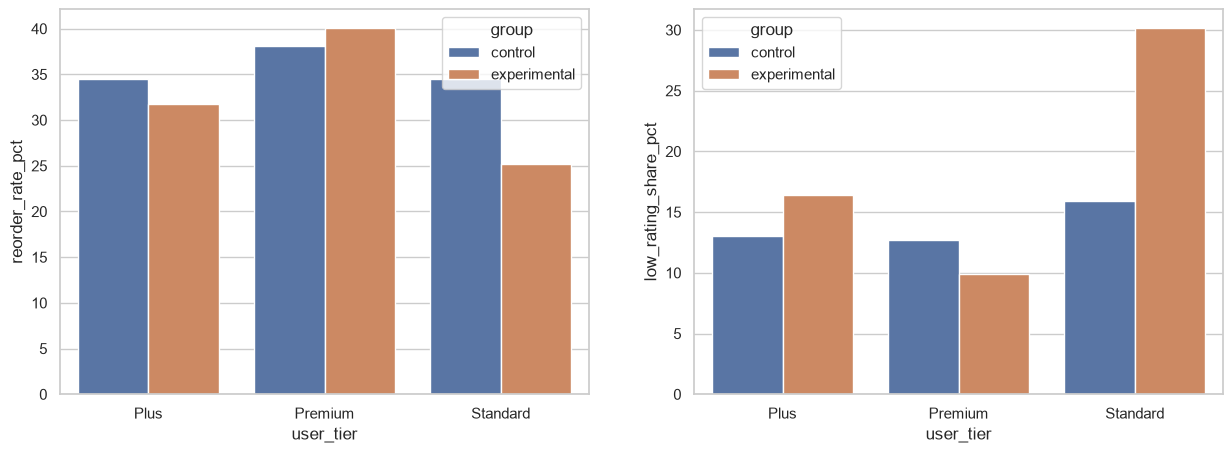

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=df_grouped, x="user_tier", y="reorder_rate_pct", hue="group", errorbar=None, ax=axes[0])
sns.barplot(data=df_grouped, x="user_tier", y="low_rating_share_pct", hue="group", errorbar=None, ax=axes[1]);

In [16]:
df_clean.groupby("group", as_index=False).agg(
    reorder_rate_pct=("reordered_within_7d", lambda x: x.mean() * 100)
)

,group,reorder_rate_pct
0,control,34.6
1,experimental,28.5


In [17]:
df_standard = df_clean.query("user_tier == 'Standard'")
chi2_res = pg.chi2_independence(df_standard, x="group", y="reordered_within_7d")
chi2_res[1]

reordered_within_7d,0,1
group,,
control,2958.5,1523.5
experimental,3255.5,1092.5


In [18]:
chi2_res[2]

,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.0,83.2,1.0,0.0,0.1,1.0
1,cressie-read,0.7,83.3,1.0,0.0,0.1,1.0
2,log-likelihood,0.0,83.5,1.0,0.0,0.1,1.0
3,freeman-tukey,-0.5,83.7,1.0,0.0,0.1,1.0
4,mod-log-likelihood,-1.0,84.1,1.0,0.0,0.1,1.0
5,neyman,-2.0,84.9,1.0,0.0,0.1,1.0


Основной удар пришелся по самому массовому сегменту `Standard`: доля плохих оценок (1-2 звезды) здесь выросла почти вдвое (с ~16% до ~30%), а 7-дневный Retention упал с 33.9% до 25.2% (-8.7 п.п., или -25.6% относительного падения).

Критерий Хи-квадрат подтверждает значимость падения ($\chi^2 \approx 83.2$, $p < 0.001$, Cramer's V = 0.097, мощность 1.0). Клиенты `Premium` с крупными чеками почти не пострадали, поэтому на общем графике монетизации проблема была не видна.

## 5. Юнит-экономика и итоги

Из-за короткого окна теста (4 недели) оценить полный LTV напрямую нельзя, поэтому прикинем ожидаемое число заказов на пользователя через геометрическую прогрессию $1 / (1 - p)$, где $p$ - вероятность повторного заказа за 7 дней.

Для оценки чистого баланса возьмем консервативное допущение, что базовая комиссия маркетплейса с мерчантов составляет 15% от GMV.

In [19]:
stan_df = df_clean.query("user_tier == 'Standard' and cart_value < 500 and is_returned == 0")

stan_df_ltv = (
    stan_df.groupby("group")
    .agg(
        unique_users=("user_id", "nunique"),
        orders=("order_id", "count"),
        mean_fee=("service_fee", "mean"),
        mean_cart=("cart_value", "mean"),
        reorder_prob=("reordered_within_7d", "mean"),
    )
    .assign(
        expected_orders=lambda x: 1 / (1 - x["reorder_prob"]),
        expected_fee=lambda x: x["expected_orders"] * x["mean_fee"],
        expected_gmv=lambda x: x["expected_orders"] * x["mean_cart"],
    )
)
stan_df_ltv.round(3)

,unique_users,orders,mean_fee,mean_cart,reorder_prob,expected_orders,expected_fee,expected_gmv
group,,,,,,,,
control,2706,4374,3.8,41.7,0.3,1.5,5.7,63.1
experimental,2605,4226,5.0,41.0,0.3,1.3,6.7,54.8


In [20]:
diff_1k = (stan_df_ltv.loc["experimental"] - stan_df_ltv.loc["control"]) * 1000
fee_gain = diff_1k["expected_fee"]
gmv_diff = diff_1k["expected_gmv"]
merchant_loss = abs(gmv_diff) * 0.15

round(fee_gain, 2), round(gmv_diff, 2), round(-merchant_loss, 2), round(fee_gain - merchant_loss, 2)

(np.float64(963.75),
 np.float64(-8326.74),
 np.float64(-1249.01),
 np.float64(-285.27))

### Выводы

Раскатывать текущий алгоритм нельзя, эксперимент нужно откатывать и отправлять модель на доработку.

На верхнем уровне комиссия с заказа действительно выросла (медиана +$1.08, 95% ДИ `[1.02, 1.13]`, среднее +$0.56, 95% ДИ `[0.37, 0.75]`). Но произошло это за счет агрессивного завышения сбора на небольших корзинах, что вызвало ценовой шок в сегменте `Standard`.

В результате ожидаемое число заказов на пользователя снизилось с 1.51 до 1.34 (-11.6%), а ожидаемый GMV на пользователя упал на $8.25 (-13.1%). На каждую 1000 пользователей `Standard` мы получаем +$969 за счет сервисного сбора, но теряем -$8253 оборота GMV. При допущении комиссии с мерчанта в 15% потеря маржи составляет -$1238, и чистый эффект уходит в минус на -$269 на 1000 клиентов (без учета затрат на привлечение новых пользователей взамен ушедших).

Что стоит сделать дальше:
- Ограничить максимальный Take-Rate на небольших заказах (например, потолок 12-15% для корзин до $40)
- Переобучить модель с оптимизацией под ожидаемый LTV, а не разовую комиссию с заказа
- Перед следующим релизом провести повторный A/B-тест с контролем удержания и оценок в `Standard`